# Implementasi DBSCAN Clustering Menggunakan Python

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) merupakan algoritma clustering yang mengelompokkan data berdasarkan kepadatan titik-titik yang berdekatan. Algoritma ini memiliki dua keunggulan utama, yaitu tidak memerlukan penentuan jumlah cluster sebelum proses clustering dan mampu mengidentifikasi titik yang tidak termasuk dalam kelompok mana pun sebagai noise.

DBSCAN menggunakan dua parameter utama, yaitu `eps` dan `min_samples`. Parameter `eps` menentukan radius pencarian tetangga di sekitar suatu titik, sedangkan `min_samples` menentukan jumlah minimum titik dalam radius tersebut agar titik dapat dikategorikan sebagai *core point*.

Dalam contoh ini, DBSCAN diterapkan pada data sintetis dua dimensi yang terdiri atas tiga kelompok utama dan sejumlah titik tambahan yang berpotensi menjadi pencilan. Tujuannya adalah memahami proses pembentukan cluster, pengaruh parameter, dan identifikasi noise sebelum algoritma diterapkan pada dataset nyata.

300 - Jumlah data
n_samples=300 berarti menghasilkan 300 titik data. Setiap titik memiliki dua fitur numerik, yaitu koordinat pada sumbu X dan Y. Jadi, sebelum penambahan pencilan, bentuk data adalah (300, 2).

3 - Jumlah kelompok pembangkit data
centers=3 meminta fungsi pembangkit membuat tiga pusat kelompok. Angka ini merupakan informasi untuk membuat data sintetis, bukan jumlah cluster yang diberikan kepada DBSCAN.

0.60 - Tingkat penyebaran data
cluster_std=0.60 mengatur simpangan baku penyebaran titik di sekitar pusat kelompok. Nilai yang lebih kecil cenderung menghasilkan kelompok yang lebih rapat, sedangkan nilai yang lebih besar membuat kelompok lebih menyebar.

42 - Random seed
random_state=42 membuat proses pembangkitan data dapat direproduksi. Jika kode dijalankan kembali dengan parameter yang sama, data sintetis yang dihasilkan akan sama. Angka 42 tidak memiliki makna khusus dalam algoritma DBSCAN.

Inilah bagian utama algoritma DBSCAN.
eps = 0.25
Radius pencarian tetangga

Artinya, dua titik dianggap bertetangga jika jarak Euclidean antara keduanya tidak lebih dari 0,25 dalam ruang fitur yang telah distandardisasi.
\
$d(p,q)=\sqrt{(x_p-x_q)^2+(y_p-y_q)^2}$


Jika jaraknya kurang dari atau sama dengan 0,25, titik tersebut masuk dalam lingkungan eps satu sama lain. Nilai ini bukan 0,25 kilometer atau satuan geografis tertentu karena datanya sudah distandardisasi.


min_samples = 5
Kepadatan minimum

Artinya, suatu titik harus memiliki sekurang-kurangnya lima titik dalam lingkungan eps, termasuk titik itu sendiri, agar menjadi core point.

Misalnya, jika sebuah titik memiliki empat tetangga lain dalam radius eps, jumlah totalnya adalah lima titik termasuk dirinya. Titik tersebut memenuhi syarat sebagai core point

Jumlah data: 315
Jumlah cluster: 3
Jumlah noise: 11
Noise: 11
Cluster 0: 102 data
Cluster 1: 101 data
Cluster 2: 101 data


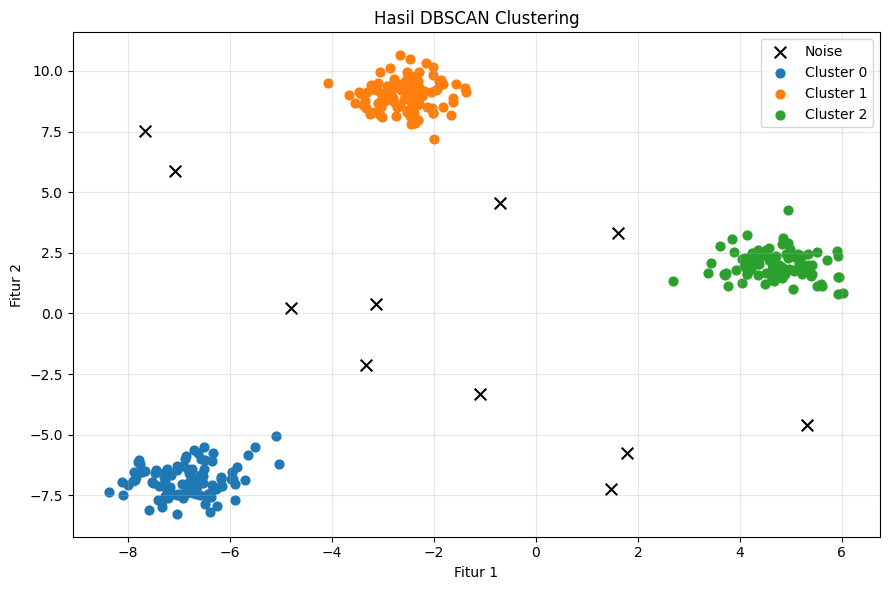

In [1]:

# =========================================================
# 1. IMPORT LIBRARY
# =========================================================
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

# =========================================================
# 2. MEMBUAT DATA SINTETIS
# =========================================================
X, _ = make_blobs(
    n_samples=300,
    centers=3,
    cluster_std=0.60,
    random_state=42
)

# Menambahkan beberapa titik pencilan
rng = np.random.RandomState(42)
outliers = rng.uniform(
    low=-8, high=8, size=(15, 2)
)

X = np.vstack([X, outliers])

# =========================================================
# 3. NORMALISASI DATA
# =========================================================
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# =========================================================
# 4. PROSES DBSCAN CLUSTERING
# =========================================================
dbscan = DBSCAN(
    eps=0.25,
    min_samples=5
)

labels = dbscan.fit_predict(X_scaled)

# =========================================================
# 5. MENAMPILKAN HASIL
# =========================================================
unique_labels = set(labels)

n_clusters = len(unique_labels - {-1})
n_noise = np.sum(labels == -1)

print("Jumlah data:", len(X))
print("Jumlah cluster:", n_clusters)
print("Jumlah noise:", n_noise)

for label in sorted(unique_labels):
    if label == -1:
        print("Noise:", np.sum(labels == label))
    else:
        print(
            f"Cluster {label}:",
            np.sum(labels == label),
            "data"
        )

# =========================================================
# 6. VISUALISASI HASIL CLUSTERING
# =========================================================
plt.figure(figsize=(9, 6))

for label in sorted(unique_labels):
    mask = labels == label

    if label == -1:
        plt.scatter(
            X[mask, 0], X[mask, 1],
            color="black", marker="x",
            s=70, label="Noise"
        )
    else:
        plt.scatter(
            X[mask, 0], X[mask, 1],
            s=40, label=f"Cluster {label}"
        )

plt.title("Hasil DBSCAN Clustering")
plt.xlabel("Fitur 1")
plt.ylabel("Fitur 2")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
